In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

# Data Loading and exploration 

In [2]:
# Loading in the dataset and viewing the first few rows

data = pd.read_csv("dataset_olympics.csv")
data.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [3]:
# Getting the basic information about the datasets
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      70000 non-null  int64  
 1   Name    70000 non-null  str    
 2   Sex     70000 non-null  str    
 3   Age     67268 non-null  float64
 4   Height  53746 non-null  float64
 5   Weight  52899 non-null  float64
 6   Team    70000 non-null  str    
 7   NOC     70000 non-null  str    
 8   Games   70000 non-null  str    
 9   Year    70000 non-null  int64  
 10  Season  70000 non-null  str    
 11  City    70000 non-null  str    
 12  Sport   70000 non-null  str    
 13  Event   70000 non-null  str    
 14  Medal   9690 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 14.6 MB


In [4]:
# Getting the summary stats by column 
data.describe()

,ID,Age,Height,Weight,Year
count,70000.000000,67268.000000,53746.000000,52899.000000,70000.000000
mean,18081.846986,25.644645,175.505303,70.900216,1977.766457
std,10235.613253,6.485239,10.384203,14.217489,30.103306
min,1.000000,11.000000,127.000000,25.000000,1896.000000
25%,9325.750000,21.000000,168.000000,61.000000,1960.000000
50%,18032.000000,25.000000,175.000000,70.000000,1984.000000
75%,26978.000000,28.000000,183.000000,79.000000,2002.000000
max,35658.000000,88.000000,223.000000,214.000000,2016.000000


In [5]:
# Describe the data and include the objects 
data.describe(include=['object'])

/var/folders/1w/lrpq1gv15cn10njb1pv9_pd00000gn/T/ipykernel_85779/3085099771.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.describe(include=['object'])


,Name,Sex,Team,NOC,Games,Season,City,Sport,Event,Medal
count,70000,70000,70000,70000,70000,70000,70000,70000,70000,9690
unique,35556,2,827,226,51,2,42,65,744,3
top,Oksana Aleksandrovna Chusovitina,M,United States,USA,2016 Summer,Summer,London,Athletics,Football Men's Football,Gold
freq,29,51877,4979,5216,3675,58467,6034,10629,1738,3292


# Data Cleaning 

In [6]:
# Checking for missing values and determining what missing and if any should be filled
data.isnull().sum()

ID            0
Name          0
Sex           0
Age        2732
Height    16254
Weight    17101
Team          0
NOC           0
Games         0
Year          0
Season        0
City          0
Sport         0
Event         0
Medal     60310
dtype: int64

In [7]:
# Checking for duplicates rows 
data.duplicated().sum()


np.int64(383)

In [8]:
# Cleaning the duplicated rows 
data.drop_duplicates(inplace=True)

In [9]:
# Double checking if there is anymore duplicated rows
data.duplicated().sum()

np.int64(0)

# Data visualization

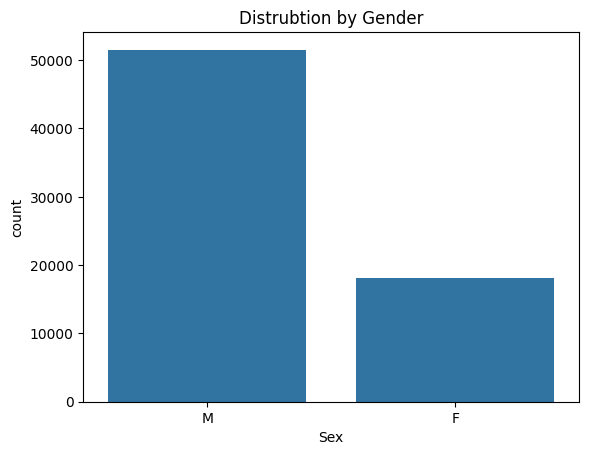

In [10]:
# Visualizing the data 
sns.countplot(data = data, x = 'Sex')
plt.title("Distrubtion by Gender")
plt.show()

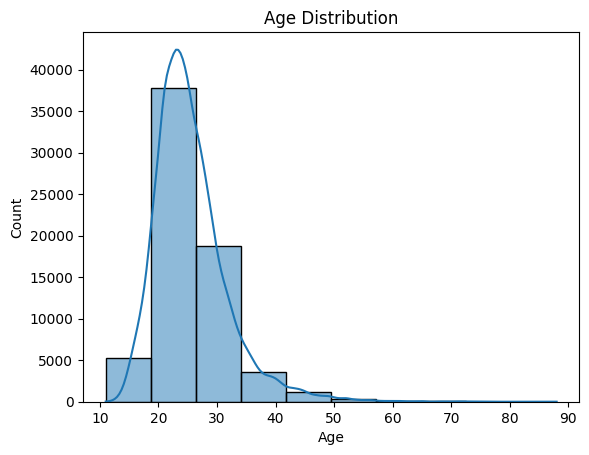

In [11]:
# Using a histogram plot to show the distribution of medals because it is a numerical column
sns.histplot(data = data, x ='Age', bins = 10, kde=True)
plt.title("Age Distribution")
plt.show()

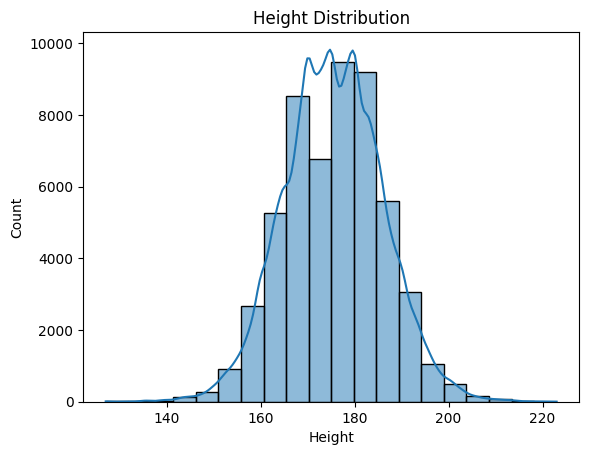

In [12]:
# Height distrubution 
sns.histplot(data = data, x = 'Height', bins = 20, kde=True)
plt.title('Height Distribution')
plt.show()

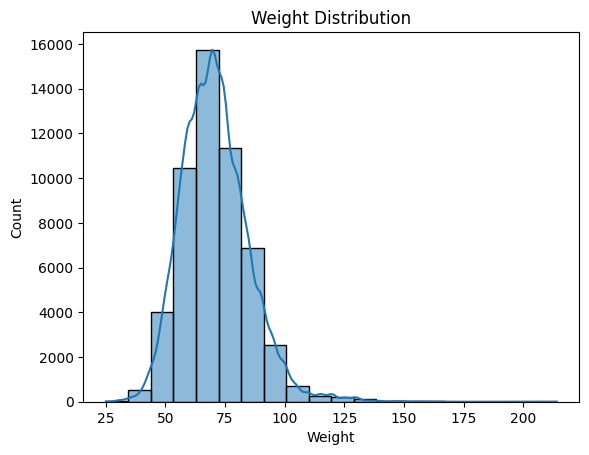

In [13]:
# Weight distrubtion 
sns.histplot(data = data, x = 'Weight', bins = 20, kde = True)
plt.title('Weight Distribution')
plt.show()

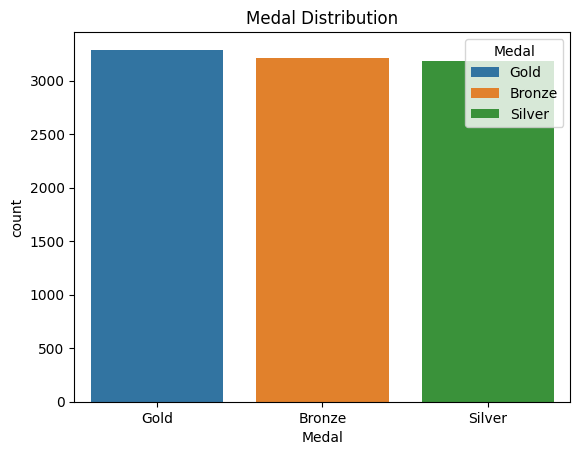

In [14]:
# Medal Distribution
sns.countplot(data=data, x='Medal', hue='Medal')
plt.title('Medal Distribution')
plt.show()

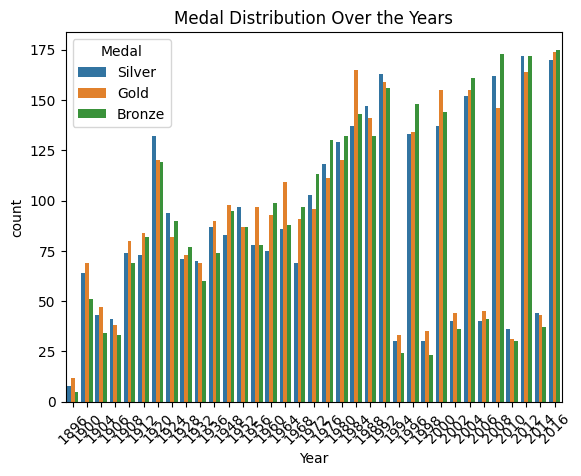

In [15]:
# Medal distribution over the years
sns.countplot(data=data, x='Year', hue='Medal')
plt.title('Medal Distribution Over the Years')
plt.xticks(rotation=45)
plt.show()

# Data Grouping and filtering 

In [16]:
# Grouping by year and the participating countries
year_avg_age = data.groupby('Year')['Age'].mean()
print(year_avg_age)

Year
1896    23.029412
1900    29.119883
1904    27.063241
1906    26.989474
1908    27.000000
1912    27.965552
1920    29.241135
1924    28.252267
1928    27.973564
1932    29.606987
1936    27.245665
1948    28.363170
1952    26.273684
1956    26.316156
1960    25.136156
1964    24.852107
1968    24.316722
1972    24.126448
1976    23.656820
1980    23.312364
1984    24.060328
1988    24.257374
1992    24.637827
1994    24.487516
1996    25.338210
1998    25.143860
2000    25.435177
2002    26.029095
2004    25.780111
2006    26.091716
2008    25.685148
2010    26.150776
2012    25.993485
2014    26.082814
2016    26.259592
Name: Age, dtype: float64


In [17]:
# Grouping by sport and participants height
sport_median_height = data.groupby('Sport')['Height'].median()
print(sport_median_height.min())

164.0


In [18]:
# Filtering by median height 
sport_median_height[sport_median_height == 164]

Sport
Gymnastics    164.0
Name: Height, dtype: float64

In [19]:
# Grouping male and female athletes by country
country_gender_count = data.groupby(['NOC', 'Sex'])["ID"].count()
print(country_gender_count)

NOC  Sex
AFG  M       38
AHO  F        6
     M       27
ALB  F        4
     M        7
           ... 
YUG  M      455
ZAM  F        3
     M       40
ZIM  F       41
     M       47
Name: ID, Length: 432, dtype: int64


In [20]:
# Most gold winning country 
country_gold_medals = data[data["Medal"] == "Gold"].groupby("NOC")["Medal"].count()
print(country_gold_medals.max())

747


In [21]:
# What country won the most gold medals?
country_gold_medals[country_gold_medals == 747]

NOC
USA    747
Name: Medal, dtype: int64

In [22]:
# Grouping by sport and finding the average weight by sex's 
sport_gender_avg_weight = data.groupby(['Sport', 'Sex'])['Weight'].mean()
print(sport_gender_avg_weight)

Sport          Sex
Alpine Skiing  F      62.154589
               M      77.725309
Alpinism       F            NaN
               M            NaN
Archery        F      61.023256
                        ...    
Water Polo     M      87.584973
Weightlifting  F      66.189474
               M      79.927852
Wrestling      F      58.169014
               M      77.256240
Name: Weight, Length: 114, dtype: float64


In [23]:
# Grouping by sport and finding the average weight by sex's but by specific sport
sport_gender_avg_weight = data.groupby(['Sport', 'Sex'])['Weight'].mean()
print(sport_gender_avg_weight["Wrestling"])

Sex
F    58.169014
M    77.256240
Name: Weight, dtype: float64


In [24]:
# Grouping by sport and finding the average weight for each sport and gender
sport_gender_avg_weight = data.groupby(['Sport', 'Sex'])['Weight'].mean()
print(sport_gender_avg_weight["Wrestling"]["F"])

58.16901408450704


# Visualizing group trends

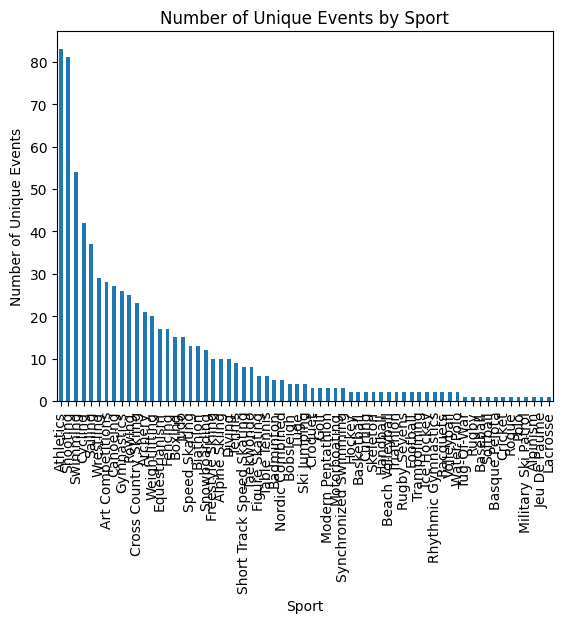

In [25]:
# Grouping by sport and count # of unique events
sport_events_count = data.groupby('Sport')['Event'].nunique().sort_values(ascending=False)
sport_events_count.plot(kind = "bar")
plt.title("Number of Unique Events by Sport")
plt.xlabel("Sport")
plt.ylabel("Number of Unique Events")
plt.show()

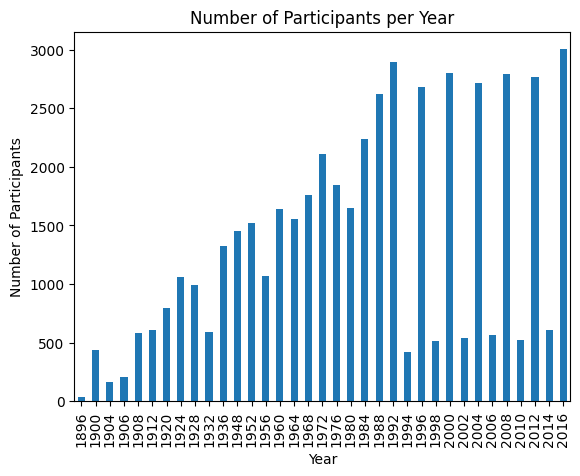

In [26]:
# Grouping by year and visualizing the number of participants
year_participants_count = data.groupby('Year')['ID'].nunique()
year_participants_count.plot(kind = "bar")
plt.title("Number of Participants per Year")
plt.xlabel("Year")
plt.ylabel("Number of Participants")
plt.show()

# Advnaced data analysis

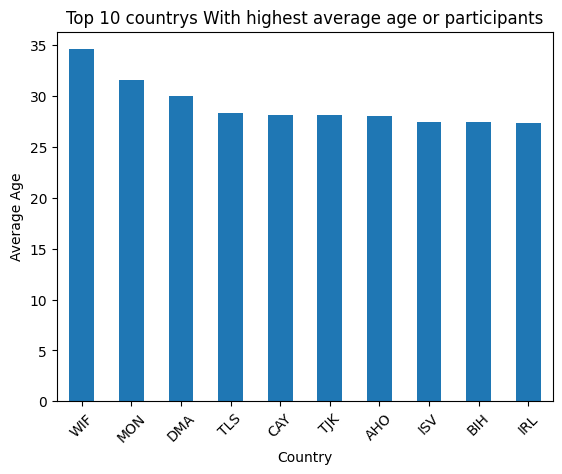

In [27]:
# Visualizing the average by participant top 10
country_avg_age = data.groupby('NOC')['Age'].mean().sort_values(ascending = False)
country_avg_age.head(10).plot(kind='bar')
plt.title('Top 10 countrys With highest average age or participants')
plt.xlabel('Country')
plt.ylabel('Average Age')
plt.xticks(rotation=45)
plt.show()

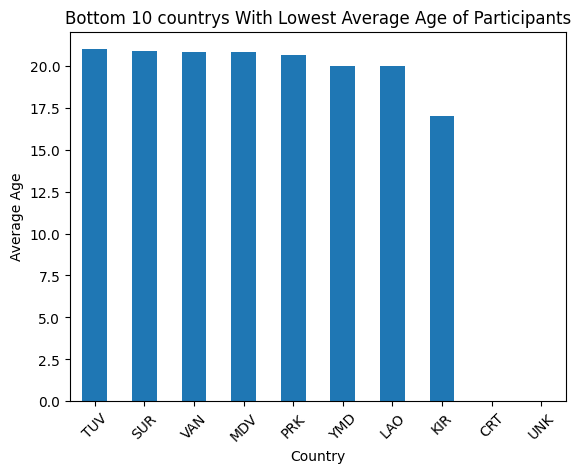

In [28]:
# Visualizing the average by participant by bottom 10
country_avg_age = data.groupby('NOC')['Age'].mean().sort_values(ascending = False)
country_avg_age.tail(10).plot(kind='bar')
plt.title('Bottom 10 countrys With Lowest Average Age of Participants')
plt.xlabel('Country')
plt.ylabel('Average Age')
plt.xticks(rotation=45)
plt.show()

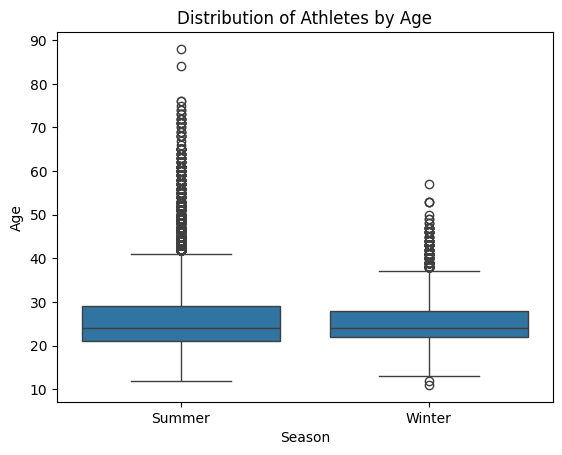

In [29]:
# Grouping by season and plot the distribution of athletes by ages
sns.boxplot(data=data, x='Season', y='Age')
plt.title('Distribution of Athletes by Age')
plt.xlabel('Season')
plt.ylabel('Age')
plt.show()

/var/folders/1w/lrpq1gv15cn10njb1pv9_pd00000gn/T/ipykernel_85779/3603909411.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data, x='Medal', y='Height', palette='Set2')


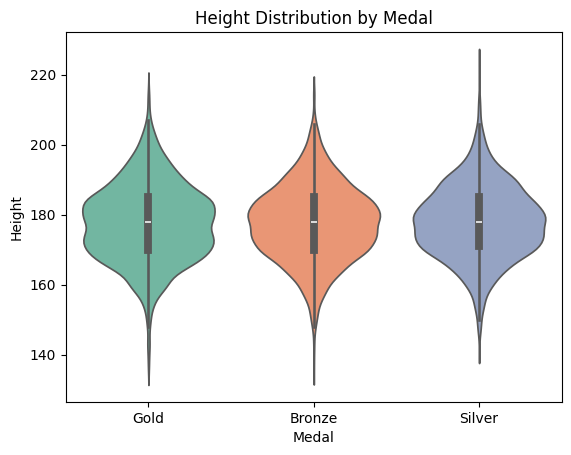

In [30]:
# Grouping by medal and display the distribution of heights
sns.violinplot(data=data, x='Medal', y='Height', palette='Set2')
plt.title('Height Distribution by Medal')
plt.xlabel('Medal')
plt.ylabel('Height')
plt.show()

# Retrieve specific statistics

In [31]:
# The most meddal winning country 
most_medals_country = data["NOC"].value_counts().idxmax()
print(f"Most meddal winning country: {most_medals_country}")

Most meddal winning country: USA


In [32]:
# The tallest athlete is
tallest_athlete = data[data['Height'] == data['Height'].max()]
print(f"Tallest athlete: {tallest_athlete['Name'].values[0]} with height {tallest_athlete['Height'].values[0]}cm")

Tallest athlete: Tommy Loren Burleson with height 223.0cm


In [33]:
# The heaviest weight athlete
heaviest = data[data['Weight'] == data['Weight'].max()]
print(f"{heaviest['Name'].iloc[0]} is the heaviest weight athlete at {heaviest['Weight'].iloc[0]} kg")

Ricardo Blas, Jr. is the heaviest weight athlete at 214.0 kg


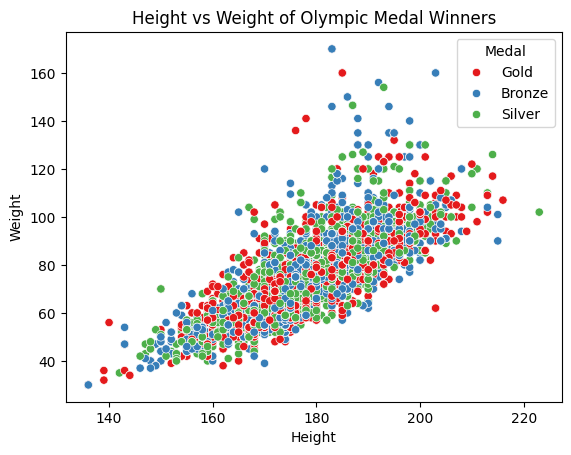

In [35]:
# Getting the height and weight of the winning athletes
sns.scatterplot(data=data, x='Height', y='Weight', hue='Medal', palette='Set1')
plt.title('Height vs Weight of Olympic Medal Winners')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.show()

# Heatmap of Olympic Medals by Country and Year

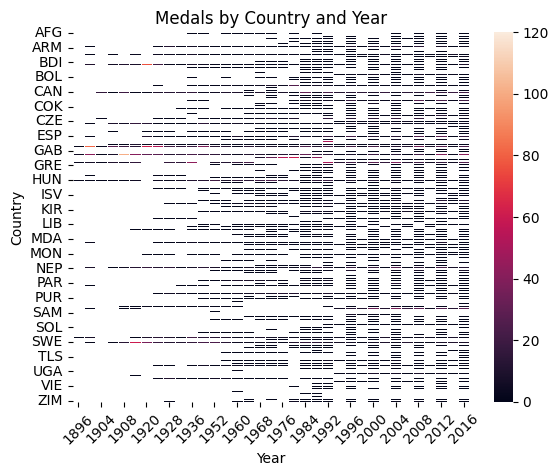

In [41]:
medals_by_country_year = data.pivot_table(index='NOC', columns='Year', values='Medal', aggfunc='count')
sns.heatmap(medals_by_country_year, linewidths=0.5)
plt.title('Medals by Country and Year')
plt.xlabel('Year')
plt.ylabel('Country')
plt.xticks(rotation=45)
plt.show()